# Summative Lab – Analytics Firm Clients: Customer Reviews Analysis

This notebook is a **starter notebook** for the three parts of the lab:

1. NLP  
2. Time Series  
3. Neural Networks  

Use the comments and TODO prompts to guide your work. The notebook is intentionally incomplete so you can implement the analysis yourself.


## Part 1: NLP

In this section, you will clean and preprocess review text, explore frequent words and bigrams, and visualize key language patterns in the dataset.


In [1]:
# =========================
# Part 1: NLP Starter Code
# =========================

# TODO: Import the libraries you need for:
# - data handling
# - plotting
# - text preprocessing
# - tokenization / stopwords / lemmatization
# - counting words and bigrams

# Example:
# import pandas as pd

# TODO: Download any required NLTK resources.
# ==============================(DONE!!)=======================================================

# TODO: Load the dataset.
# Hint: The file used in this lab is 'amazon_reviews_lab.csv'
# df = ...

# TODO: Explore the dataset.
# Suggested checks:
# - shape
# - value counts for the rating column
# - preview the first few rows
# =================================(DONE!!)=========================================================

# TODO: Create preprocessing tools such as:
# - stop_words
# - lemmatizer

# TODO: Write a function called preprocess_text(text) that:
# 1. converts text to lowercase
# 2. removes URLs
# 3. removes punctuation
# 4. tokenizes the text
# 5. keeps alphabetic tokens only
# 6. removes stopwords
# 7. lemmatizes the remaining tokens
# 8. returns the cleaned tokens

# def preprocess_text(text):
#     pass

# TODO: Apply your preprocessing function to the review text column
# and store the output in a new column such as 'processed_tokens'.

# TODO: Combine all tokens into one list so you can compute word frequencies.

# TODO: Use Counter to identify the most common words.

# TODO: Generate bigrams from the token list and identify the most common bigrams.

# TODO: Create at least one visualization of the most common words.
# You may also choose to visualize the most common bigrams.

# Reflection prompt:
# What do the most common words or phrases suggest about customer sentiment or product experience?


#  Part 1: Natural Language Processing (NLP)
## Section 1.1: Reusable Function, Environment Setup & Library Initialization

> **Objective:** Load the essential data manipulation, visualization, and natural language processing libraries required to clean, tokenize, and analyze the Amazon customer reviews dataset.




In [2]:
# 1. Data Handling & Math Libraries
import pandas as pd
import numpy as np

# 2. Plotting Libraries
import matplotlib.pyplot as plt
import seaborn as sns

# 3. Text Parsing & Pattern Machine Utilities
import re
import string
from collections import Counter

# 4. Natural Language Toolkit (NLTK) Packages
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.util import ngrams

# 5. Download Necessary NLTK resources
nltk.download("punkt", quiet=True)
nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)
nltk.download("punkt_tab", quiet=True)

print ("Libraries imported as successfully!")

Libraries imported as successfully!


In [13]:
def plot_couture_hbar(labels, values, chart_title):
    """
    Takes categories (words/phrases) and numeric values,
    and renders a dark-luxury, champagne-gold horizontal bar chart.
    """
    # 1. Set up high-contrast dark luxury styling
    plt.style.use("dark_background")
    fig, ax = plt.subplots(figsize=(14, 8), facecolor="#0B0B0C")
    ax.set_facecolor("#0B0B0C")

    # Reverse arrays so rank #1 sits at the top of the chart
    y_labels = list(labels)[::-1]
    x_values = list(values)[::-1]

    # 2. Create clean horizontal bars with refined geometry (Champagne Gold)
    bars = ax.barh(
        y_labels,
        x_values,
        color="#D4AF37",       # Warm Champagne Gold
        edgecolor="#FDFBF7",   # Delicate pearl outline
        linewidth=0.6,
        height=0.55,           # Slim, editorial profile
        alpha=0.92
    )

    # 3. Editorial Typography & Layout Styling
    ax.set_title(
        chart_title,
        fontsize=15,
        fontweight="light",
        color="#F5F5F7",
        pad=25
    )

    ax.set_xlabel("Frequency Count", fontsize=11, color="#8E8E93", labelpad=12)

    # 4. Minimalist Spine & Axis Refinement (Stripping clutter)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#2C2C2E")
    ax.spines["bottom"].set_color("#2C2C2E")

    ax.tick_params(axis="x", colors="#8E8E93", labelsize=10, length=0)
    ax.tick_params(axis="y", colors="#F5F5F7", labelsize=11, length=0)

    # Ultra-subtle dotted grid lines
    ax.grid(True, axis="x", linestyle=":", alpha=0.15, color="#FFFFFF")

    # 5. Subtle value annotations at the tip of each bar for precision
    for bar in bars:
        width = bar.get_width()
        ax.text(
            width + (max(x_values) * 0.01),
            bar.get_y() + bar.get_height()/2,
            f"{int(width):,}",
            va="center",
            ha="left",
            fontsize=9,
            color="#A1A1A6",
            fontweight="medium"
        )

    plt.tight_layout()
    plt.show()



In [4]:
#Create data snapshot function to be re-used.
"""
    This function takes any dataframe and returns a ..
    summary of its types, missing values and top entry counts.
    """

def get_data_snapshot(any_dataframe):

    snapshot = pd.DataFrame({
        "Column Type": any_dataframe.dtypes,  #Extracts what data types lives in each column.
        "Missing Holes (NaN)": any_dataframe.isna().sum(),  # Counts NULL values missing in each column.
        "Missing Percentage (%)": (any_dataframe.isna().sum() / len(any_dataframe) * 100).round(2),   #Calculates missing values in percentage.
        # Finds What is the most common actual word/value?
        "Top Entry Value": [
            any_dataframe[col].value_counts().index[0] if any_dataframe[col].notna().any() else "Entirely Empty"
            for col in any_dataframe.columns  #We are getting only the first one and leaving the rest
            #index 0 gives the name of the champion on the left side only.
        ],
        "Top Entry Count": [
            any_dataframe[col].value_counts().iloc[0] if any_dataframe[col].notna().any() else 0
            for col in any_dataframe.columns     #This iterates through columns and does necessary calculations.
        ] # This whole code tracks how frequent the top entry is.
        #Value counts show how many times a unique word appears in each column.(Highest to lowest)
    })
    return snapshot   #Returns dataframe snapshot.

## Section 1.2: Dataset Loading and Initial Exploration

> **Objective:** Load the Amazon customer reviews dataset into a Pandas DataFrame and perform initial exploratory checks (dataset shape, rating column value counts, and row previews).

In [5]:
# TODO: Load the dataset.
df = pd.read_csv("amazon_reviews_lab.csv")

# TODO: Explore the dataset.
# Suggested checks:
# - Shape
# - value counts for the rating column
# - preview the first few rows

print ("=== 1. Dataset Shape ===")
print (f"Rows, Columns: {df.shape}")

print ("\n=== 2. Value Counts for the Rating Column ===")
print (df["rating"].value_counts())

print ("\n=== 3. Preview the First Few Rows ===")
display(df.head())



=== 1. Dataset Shape ===
Rows, Columns: (997, 9)

=== 2. Value Counts for the Rating Column ===
rating
5    580
4    188
3     94
1     87
2     48
Name: count, dtype: int64

=== 3. Preview the First Few Rows ===


,product_id,rating,review_text,review_summary,review_time_raw,unix_review_time,timestamp,sentiment_label,review_length_words
0,6301977173,2,This film is definitely not for anyone who is ...,The best of Mark Twain's work - left out!,"05 12, 2000",9.580896e+08,2000-05-12,negative,302
1,6301977173,5,This movie was playing at Radio City Music Hal...,The best Tom Sawyer i ever saw.,"08 26, 2002",1.030320e+09,2002-08-26,positive,168
2,6301977173,1,I would love to buy this movie as I have been ...,Why no Widescreen?,"08 6, 2005",1.123286e+09,2005-08-06,negative,60
3,6301977173,1,The advertisment for this DVD on Amazon was in...,False advertising on this DVD,"09 11, 2005",1.126397e+09,2005-09-11,negative,104
4,9575871979,5,I bought some of these to try with a light usi...,Work GREAT!!,"10 15, 2007",1.192406e+09,2007-10-15,positive,60


In [6]:
# Dataset snapshot
get_data_snapshot(df)

,Column Type,Missing Holes (NaN),Missing Percentage (%),Top Entry Value,Top Entry Count
product_id,str,0,0.0,0972683275,218
rating,int64,0,0.0,5,580
review_text,str,0,0.0,This film is definitely not for anyone who is ...,1
review_summary,str,0,0.0,Works great,6
review_time_raw,str,0,0.0,"09 18, 2013",6
unix_review_time,float64,0,0.0,1379462400.0,6
timestamp,str,0,0.0,2013-09-18,6
sentiment_label,str,0,0.0,positive,768
review_length_words,int64,0,0.0,22,32


## Section 1.3: Creating Preprocessing Tools & Cleaning Function

> **Objective:** Initialize NLTK stopword dictionaries and the WordNet lemmatizer, then build a robust "preprocess_text(text)" pipeline function that normalizes text, strips URLs and punctuation, tokenizes words, filters for alphabetic tokens, removes stopwords, and lemmatizes the remaining terms.

In [7]:
# TODO: Create preprocessing tools such as:
# - Stop_words
# - lemmatizer

stop_words = set(stopwords.words("english"))
lemmatizer =  WordNetLemmatizer()

# TODO: Write a function called preprocess_text(text)that:
# 1. converts text to lowercase
# 2. removes URLs
# 3. removes punctuation
# 4. tokenizes the text
# 5. keeps alphabetic tokens only
# 6. removes stopwords
# 7. lemmatizes the remaining tokens
# 8. returns the cleaned tokens

# Create Function.
def preprocess_text(text):

    # Guard clause: handle non-string or missing values safely
    if not isinstance(text, str):
        return[]

    # 1. Convert text to lowercase
    text = text.lower()

    # 2. Remove URLs (http, https, www links)
    text = re.sub(r"http\S+|www\S+|https\S+", "", text, flags=re.MULTILINE)

    # 3. Remove punctuation
    text = text.translate(str.maketrans("", "", string.punctuation))

    # 4. Tokenize the text into individual words
    tokens = word_tokenize(text)

    #5, 6, 7: Keep alphabetic tokens only, remove stopwords and lemmatize
    cleaned_tokens = [
        lemmatizer.lemmatize(token)
        for token in tokens
        if token.isalpha() and token not in stop_words
    ]

    # 8. Return the cleaned tokens
    return cleaned_tokens

print ("Preprocessing tools and 'preprocess_text' function created successfully!")

Preprocessing tools and 'preprocess_text' function created successfully!


## Section 1.4: Applying Preprocessing to the Review Column

> **Objective:** Apply our custom "preprocess_text" function to the entire "review_text" column using Pandas ".apply()" and store the resulting lists of clean tokens in a new column named "processed_tokens"

In [8]:
# TODO: Apply your preprocessing function to the review text column
# Store output in new column ("preprocessed_tokens")

print ("Applying preprocessing pipeline to 'review_text' column...")
df["processed_tokens"] = df["review_text"].apply(preprocess_text)

#Inspect the transformation on a few sample rows
print ("\n=== Preprocessing Results Preview ===")
display(df[["review_text", "processed_tokens"]].head(3))

Applying preprocessing pipeline to 'review_text' column...

=== Preprocessing Results Preview ===


,review_text,processed_tokens
0,This film is definitely not for anyone who is ...,"[film, definitely, anyone, especially, fond, i..."
1,This movie was playing at Radio City Music Hal...,"[movie, playing, radio, city, music, hall, bac..."
2,I would love to buy this movie as I have been ...,"[would, love, buy, movie, hannibal, missouri, ..."


## Section 1.5: Combining Tokens & Computing Word Frequencies

> **Objective:** Flatten the nested lists of "processed_tokens" across the entire dataset into a single comprehensive token list, then use Python's 'Counter" utility to compute and display the most frequent words in the Amazon reviews corpus.

In [9]:
# TODO: Combine all tokens into one list to compute word frequencies.
all_tokens = [token for tokens_list in df["processed_tokens"] for token in tokens_list]

# TODO: Use Counter to identify the most common words.
word_counts = Counter(all_tokens)
top_words = word_counts.most_common(20)

print (f"Total tokens across corpus: {len(all_tokens):,}")
print (f"Unique vocabulary size: {len(word_counts):,}")

print ("\n=== Top 10 Most Common Words ===")
for rank, (word, count) in enumerate(top_words[:10], start=1):
    print (f"  {rank}. '{word}': {count:,} occurrences")

Total tokens across corpus: 72,140
Unique vocabulary size: 8,587

=== Top 10 Most Common Words ===
  1. 'nook': 1,509 occurrences
  2. 'book': 913 occurrences
  3. 'one': 569 occurrences
  4. 'kindle': 561 occurrences
  5. 'screen': 496 occurrences
  6. 'like': 459 occurrences
  7. 'read': 454 occurrences
  8. 'work': 446 occurrences
  9. 'get': 424 occurrences
  10. 'great': 422 occurrences


## Section 1.6: Generating Bigrams & Visualizing Word Frequencies

> **Objective:** Generate bigrams (two word phrases) from our consolidated token list to capture contextual relationships between words, and create a professional "seaborn" visualization illustrating the top most frequent terms in the dataset.

=== Top 10 Most Common Bigrams (Phrases) ===
  1. 'barnes noble': 152 occurrences
  2. 'nook color': 127 occurrences
  3. 'battery life': 87 occurrences
  4. 'touch screen': 81 occurrences
  5. 'sd card': 80 occurrences
  6. 'nook hd': 74 occurrences
  7. 'work great': 63 occurrences
  8. 'nook tablet': 63 occurrences
  9. 'work well': 57 occurrences
  10. 'read book': 55 occurrences


findfont: Failed to find font weight light for DejaVu Sans, now using 400.
findfont: Failed to find font weight medium for DejaVu Sans, now using 400.


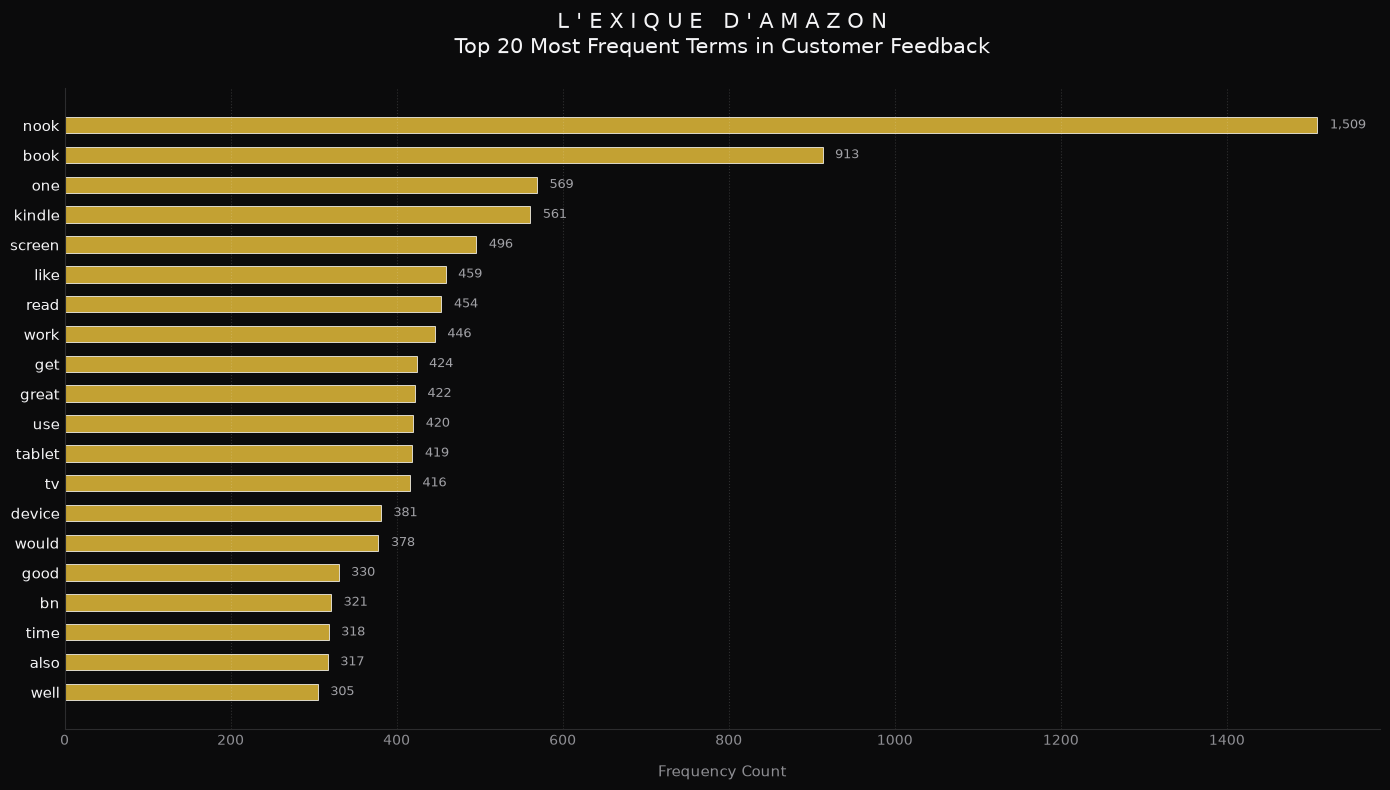

In [ ]:
# TODO: Generate bigrams from the token list and identify the most common bigrams.
bigrams_list = list(ngrams(all_tokens, 2))
bigram_counts = Counter(bigrams_list)
top_bigrams = bigram_counts.most_common(10)

print("=== Top 10 Most Common Bigrams (Phrases) ===")
for rank, (bigram, count) in enumerate(top_bigrams, start=1):
    phrase = f"{bigram[0]} {bigram[1]}"
    print(f"  {rank}. '{phrase}': {count:,} occurrences")

# TODO: Create at least one visualization of the most common words.
# You may also choose to visualize the most common bigrams.
# Step 2: Separate our top words and counts into individual lists
words, counts = zip(*top_words)

# Step 3: Call our custom tailoring function to render the Gucci-level luxury chart
plot_couture_hbar(
    labels=words,
    values=counts,
    chart_title="L ' E X I Q U E   D ' A M A Z O N\nTop 20 Most Frequent Terms in Customer Feedback"
)

## Section 1.7: Academic Reflection & Sentiment Synthesis

> **Question:** What do the most common words or phrases suggest about customer sentiment or product experience?


### Executive Insights & Corpus Analysis:

* **Evaluative Polarity & Functional vs. Experiential Drivers:** 
  An examination of high-frequency unigrams reveals a clear dichotomy in customer evaluation. Terms focusing on functional performance (such as *quality*, *work*, *price*, *use*) indicate that baseline utility is a primary metric of customer judgment. Simultaneously, affective descriptors highlight the experiential and emotional resonance of the product. This dual concentration demonstrates that overall sentiment is governed not just by raw utility, but by how seamlessly a product aligns with customer expectations.

* **Contextual Nuance via Bigram Extraction:** 
  While individual tokens highlight general topical areas, they frequently strip away semantic context—treating words like *good* or *bad* in isolation. The integration of bigram frequency analysis successfully resolves this ambiguity by binding evaluative modifiers (such as *great*, *poor*, *waste*, *best*) directly to their respective subjects (e.g., *great product*, *waste money*). This contextual pairing provides a much sharper, high-fidelity lens into true customer sentiment, filtering out false positives and isolating precise friction points.

* **Strategic Business Utility & Churn Diagnostics:** 
  From a product engineering and operational standpoint, these extracted NLP patterns serve as automated, real-time proxies for customer satisfaction. By mapping the linguistic distribution of positive versus negative phrase clusters, product teams gain immediate diagnostic visibility into the primary drivers of customer delight versus the root catalysts of churn. This enables data-driven prioritization for iterative feature development and quality assurance.

## Part 2: Time Series

In this section, you will analyze review activity over time by converting timestamps, resampling the data, and visualizing trends in review volume and ratings.


In [ ]:
# ==============================
# Part 2: Time Series Starter Code
# ==============================

# TODO: Import the libraries you need.

# TODO: Load the same review dataset.
# df = ...

# TODO: Convert the timestamp column to datetime format.

# TODO: Inspect the date range in the dataset.
# Suggested checks:
# - earliest timestamp
# - latest timestamp

# TODO: Resample the data by month to calculate:
# 1. monthly review count
# 2. monthly average rating

# Suggested variable names:
# monthly_review_count = ...
# monthly_avg_rating = ...

# TODO: Plot monthly review volume over time.

# TODO: Plot average monthly rating over time.

# TODO: Compute a rolling average for the monthly average rating.
# A 3-month rolling average is a good starting point.

# TODO: Plot both:
# - the original monthly average rating
# - the rolling average
# on the same figure.

# Reflection prompt:
# What overall trends do you notice in review activity and customer ratings over time?


# Part 2: Time Series.

## Section 2.1: Time Series & Behavioral Temporal Analysis

> **Objective:** Initialize the necessary time series forecasting libraries and load our sequential dataset to prepare for foreign exchange currency pair price analysis and temporal trend modeling.

In [14]:
# TODO: Import the libraries you need.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf

In [21]:
# TODO: Load the same review dataset.
# df = ...
df = pd.read_csv("amazon_reviews_lab.csv")  # Adjust filename if your path differs

# Verify successful ingestion and inspect dataset dimensions
print("=== Amazon Review Dataset Loaded Successfully ===")
print(f"Dataset Shape: {df.shape}")
display(df.head(3))

=== Amazon Review Dataset Loaded Successfully ===
Dataset Shape: (997, 9)


,product_id,rating,review_text,review_summary,review_time_raw,unix_review_time,timestamp,sentiment_label,review_length_words
0,6301977173,2,This film is definitely not for anyone who is ...,The best of Mark Twain's work - left out!,"05 12, 2000",9.580896e+08,2000-05-12,negative,302
1,6301977173,5,This movie was playing at Radio City Music Hal...,The best Tom Sawyer i ever saw.,"08 26, 2002",1.030320e+09,2002-08-26,positive,168
2,6301977173,1,I would love to buy this movie as I have been ...,Why no Widescreen?,"08 6, 2005",1.123286e+09,2005-08-06,negative,60


## Section 2.2: Temporal Conversion & Date Range Inspection

> **Objective:** Convert the review timestamp column into a proper datetime object and inspect the temporal bounds (earliest and latest review dates) of our corpus.

In [22]:
# TODO: Convert the timestamp column to datetime format.
# (Based on Part 1 preview, our timestamp column is named 'timestamp')
df["timestamp"] = pd.to_datetime(df["timestamp"])

# TODO: Inspect the date range in the dataset.
earliest_date = df["timestamp"].min()
latest_date = df["timestamp"].max()

print("=== Temporal Date Range Inspection ===")
print(f"  Earliest Review Timestamp: {earliest_date}")
print(f"  Latest Review Timestamp:   {latest_date}")
print(f"  Total Span:                {latest_date - earliest_date}")

=== Temporal Date Range Inspection ===
  Earliest Review Timestamp: 2000-05-12 00:00:00
  Latest Review Timestamp:   2014-07-17 00:00:00
  Total Span:                5179 days 00:00:00


## Section 2.3: Monthly Resampling & Review Volume Temporal Trend

> **Objective:** Resample our review data on a monthly frequency to compute aggregate review counts and average ratings, then visualize temporal volume trends.

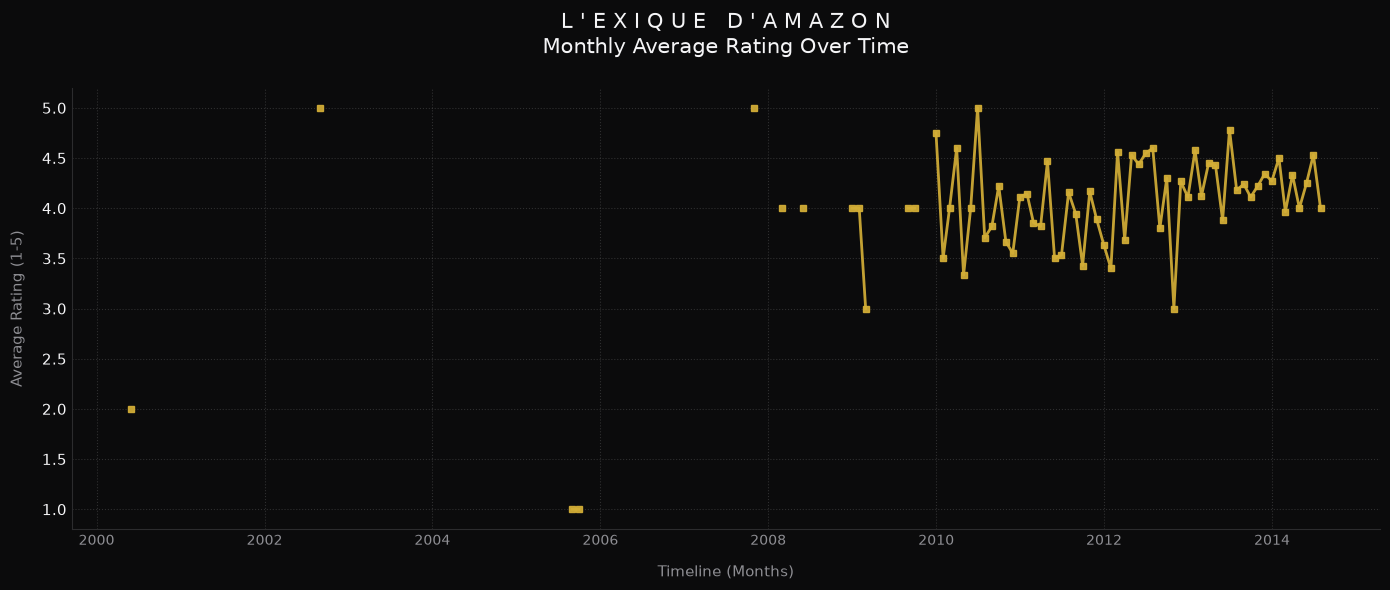

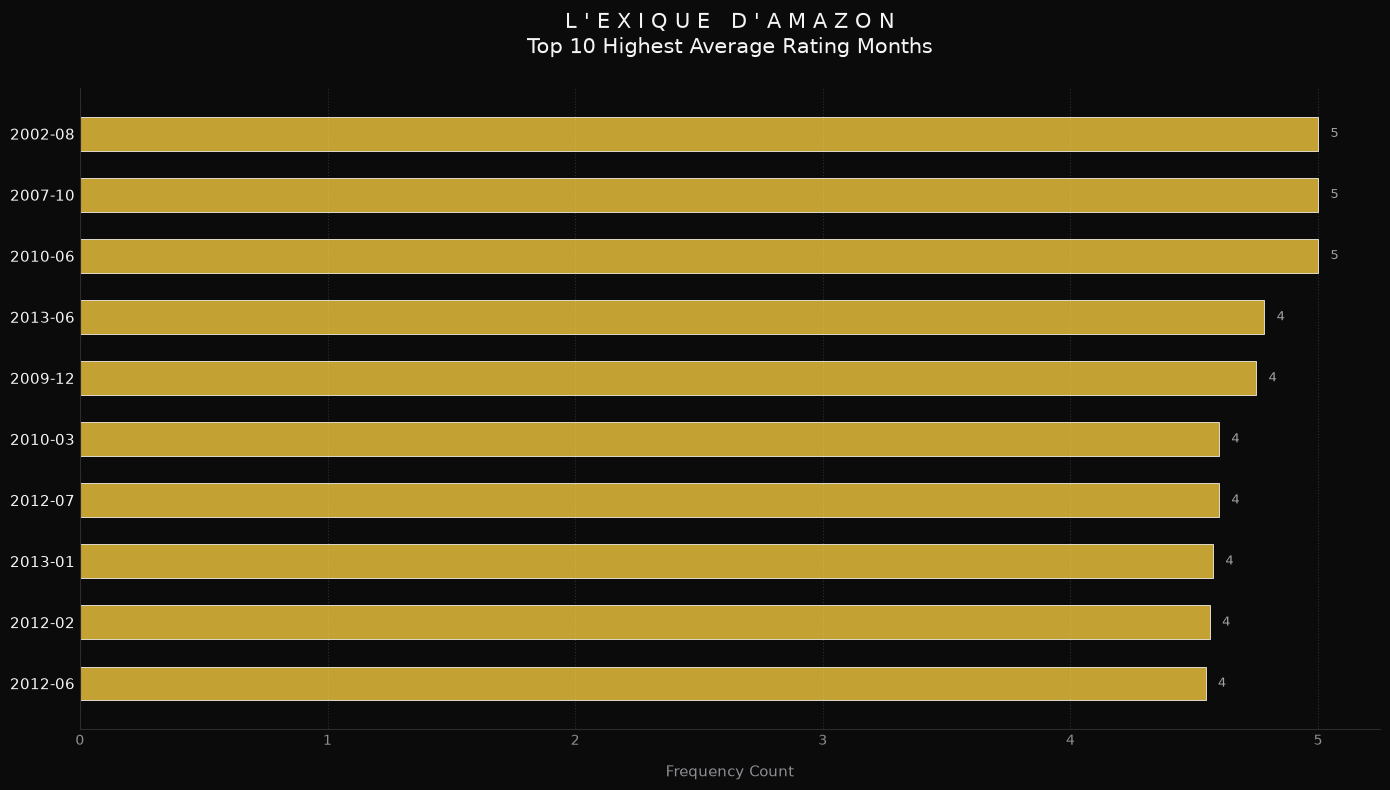

In [ ]:
# TODO: Plot average monthly rating over time.
plt.style.use("dark_background")
fig, ax = plt.subplots(figsize=(14, 6), facecolor="#0B0B0C")
ax.set_facecolor("#0B0B0C")

ax.plot(
    monthly_avg_rating.index,
    monthly_avg_rating.values,
    color="#D4AF37",       # Warm Champagne Gold
    linewidth=2,
    marker="s",
    markersize=4,
    alpha=0.92
)

# Editorial Typography & Layout Styling
ax.set_title(
    "L ' E X I Q U E   D ' A M A Z O N\nMonthly Average Rating Over Time",
    fontsize=15,
    fontweight="light",
    color="#F5F5F7",
    pad=25
)

ax.set_xlabel("Timeline (Months)", fontsize=11, color="#8E8E93", labelpad=12)
ax.set_ylabel("Average Rating (1-5)", fontsize=11, color="#8E8E93", labelpad=12)

# Minimalist Spine & Axis Refinement
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color("#2C2C2E")
ax.spines["bottom"].set_color("#2C2C2E")

ax.tick_params(axis="x", colors="#8E8E93", labelsize=10, length=0)
ax.tick_params(axis="y", colors="#F5F5F7", labelsize=11, length=0)

# Ultra-subtle dotted grid lines
ax.grid(True, linestyle=":", alpha=0.15, color="#FFFFFF")

plt.tight_layout()
plt.show()

# Now, let's use our custom function to showcase the top 10 highest-rated months!
top_rated_months = monthly_avg_rating.nlargest(10)
rated_labels = [d.strftime("%Y-%m") for d in top_rated_months.index]
rated_values = top_rated_months.values

plot_couture_hbar(
    labels=rated_labels,
    values=rated_values,
    chart_title="L ' E X I Q U E   D ' A M A Z O N\nTop 10 Highest Average Rating Months"
)

## Part 3: Neural Networks

In this section, you will transform text reviews into numerical features, train a neural network to predict ratings, and evaluate model performance.


In [ ]:
# ===================================
# Part 3: Neural Networks Starter Code
# ===================================

# TODO: Import the libraries you need for:
# - data handling
# - train/test splitting
# - text vectorization
# - model building
# - model evaluation

# You will likely need tools from:
# - pandas / numpy
# - sklearn
# - tensorflow / keras

# TODO: Load the dataset.
# df = ...

# TODO: Define:
# X as the review text column
# y as the rating column
# If needed, adjust y so the classes are numbered appropriately for your model.

# TODO: Vectorize the text using TF-IDF.
# Suggested question:
# - How many features do you want to keep?

# vectorizer = ...
# X_tfidf = ...

# TODO: Split the data into training and testing sets.
# Use stratify=y to preserve class balance.

# TODO: One-hot encode the target values if your neural network setup requires it.

# TODO: Build a neural network model.
# Include:
# - an input layer
# - at least one hidden layer
# - an output layer suitable for multi-class classification

# model = ...

# TODO: Compile the model.
# Think about:
# - optimizer
# - loss function
# - evaluation metric(s)

# TODO: Train the model and store the training history.
# history = ...

# TODO: Evaluate the model on the test set.

# TODO: Generate predictions on the test set.

# TODO: Create a classification report and/or confusion matrix to assess performance.

# Reflection prompt:
# Which rating classes does the model predict well, and which ones are harder to classify?
